# 06 Evaluation: score the diagnoses against the answer sheet

**Goal:** for every bad job in `answer_key_jobs.csv`, check whether each mode from notebook 05 named the right **cause**.

Two ways to count a correct answer:
- **strict:** the answer equals the main cause in your answer sheet.
- **lenient:** the answer equals the main cause **or** the `also_ok` cause (for bunches where two causes fit the evidence, such as worn nozzle plus low gas in late September).

Report both in Chapter 5. Lenient is fairer, strict is harder to argue with.

**Note on gradient boosting (notebook 03):** it predicts the **defect**, not the **cause**, so it isn't in this table.
It answers a different question ("will this job be bad?"). This notebook answers "why was it bad?", which a classical model can't do from the job record.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

OUT = Path("..") / "data" / "processed"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

key = pd.read_csv(OUT / "answer_key_jobs.csv").fillna({"also_ok": ""})
MODES = [m for m in ["kg_rules", "kg_llm", "llm_only"] if (OUT / f"results_{m}.csv").exists()]
res = pd.concat([pd.read_csv(OUT / f"results_{m}.csv") for m in MODES], ignore_index=True)
res = res.merge(key[["job_id", "bunch_id", "cause", "also_ok"]], on="job_id", suffixes=("", "_true"))
res["strict"] = res["cause"] == res["cause_true"]
res["lenient"] = res["strict"] | (res["cause"] == res["also_ok"])
# a citation only counts if the id was really in the evidence the mode was shown (llm_only is shown none)
if "evidence_shown" not in res:
    res["evidence_shown"] = ""
cited = res["evidence_ids"].fillna("").astype(str).str.split()
shown = res["evidence_shown"].fillna("").astype(str).str.split()
res["cites_real_evidence"] = [bool(set(c) & set(s)) for c, s in zip(cited, shown)]
print("modes found:", MODES, "|", res["job_id"].nunique(), "jobs")

modes found: ['kg_rules', 'kg_llm', 'llm_only'] | 99 jobs


## 1. The main table
- **valid:** the share of answers that named a cause from the list (an LLM can answer something else).
- **cites evidence:** the share of answers that pointed to at least one evidence id **that the mode was really shown**. That matters, because the factory asked for "evidence we can check". Made-up ids (or `llm_only` writing job settings in that field) don't count.
  Results saved before this check existed have no `evidence_shown` column and score 0 here: re-run notebook 05 for them.
- **seconds/job:** how long one answer takes.

In [2]:
summary = res.groupby("mode").agg(
    jobs=("job_id", "count"),
    strict_accuracy=("strict", "mean"),
    lenient_accuracy=("lenient", "mean"),
    valid=("cause", lambda s: (s != "invalid").mean()),
    cites_evidence=("cites_real_evidence", "mean"),
    seconds_per_job=("seconds", "mean"),
).reindex(MODES).round(3)
summary.to_csv(OUT / "evaluation_summary.csv")
summary

,jobs,strict_accuracy,lenient_accuracy,valid,cites_evidence,seconds_per_job
mode,,,,,,
kg_rules,99,0.889,1.000,1.0,1.0,0.000
kg_llm,99,0.889,1.000,1.0,1.0,6.108
llm_only,99,0.475,0.475,1.0,0.0,6.808


### Figure 6: accuracy by mode

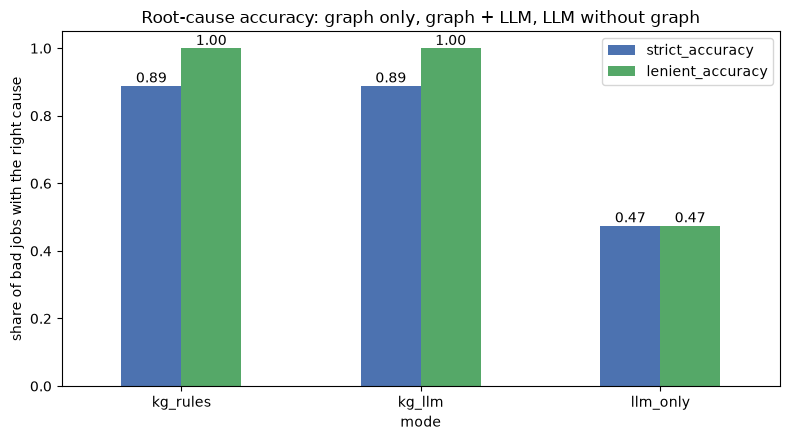

In [3]:
ax = summary[["strict_accuracy", "lenient_accuracy"]].plot(kind="bar", figsize=(8, 4.5), rot=0, color=["#4C72B0", "#55A868"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("share of bad jobs with the right cause")
ax.set_title("Root-cause accuracy: graph only, graph + LLM, LLM without graph")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f")
plt.tight_layout()
plt.savefig(FIG / "fig6_cause_accuracy.png", dpi=200)
plt.show()

## 2. Where does each mode go wrong?
Accuracy per bunch shows **which** problems are hard. A low score on one bunch usually means the evidence for that cause is weak or misleading in the graph.

In [4]:
per_bunch = res.pivot_table(index="bunch_id", columns="mode", values="lenient", aggfunc="mean")[MODES].round(2)
per_bunch["jobs"] = key["bunch_id"].value_counts()
per_bunch

mode,kg_rules,kg_llm,llm_only,jobs
bunch_id,,,,
B1,1.0,1.0,0.0,7
B2,1.0,1.0,0.0,4
B3,1.0,1.0,0.0,12
B4,1.0,1.0,1.0,4
B5,1.0,1.0,1.0,29
B6,1.0,1.0,1.0,3
B7,1.0,1.0,0.0,20
B8,1.0,1.0,1.0,11
P1,1.0,1.0,0.0,9


### Figure 7: confusion matrix of causes (your system, or the best mode available)

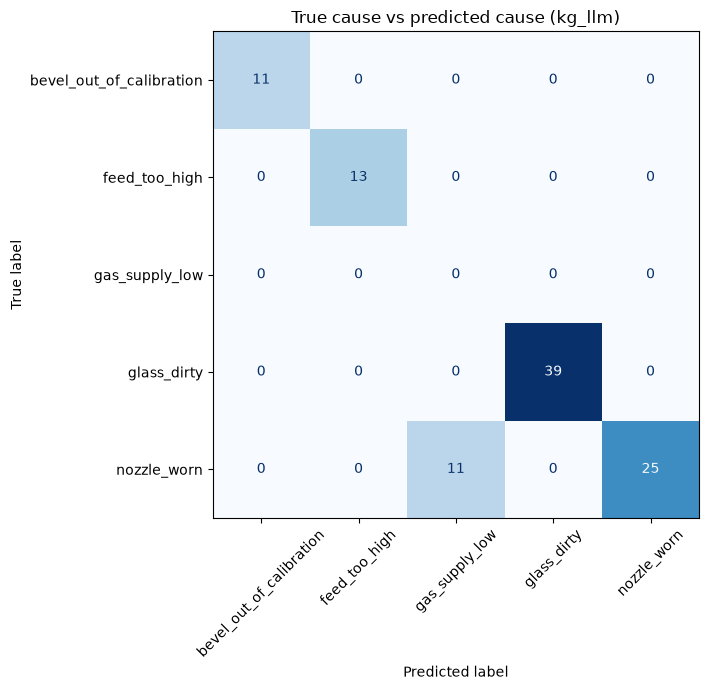

In [5]:
show = "kg_llm" if "kg_llm" in MODES else MODES[0]
d = res[res["mode"] == show]
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(d["cause_true"], d["cause"], ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title(f"True cause vs predicted cause ({show})")
plt.tight_layout()
plt.savefig(FIG / "fig7_cause_confusion.png", dpi=200)
plt.show()

## 3. Read the mistakes
Numbers only tell you *how often*. Reading the wrong answers tells you *why*, and that's what goes in the discussion chapter.

In [6]:
pd.set_option("display.max_colwidth", 140)
wrong = res[~res["lenient"]][["mode", "job_id", "bunch_id", "defect", "cause_true", "cause", "explanation"]]
print(len(wrong), "wrong answers")
wrong.sort_values(["mode", "job_id"]).head(20)

52 wrong answers


,mode,job_id,bunch_id,defect,cause_true,cause,explanation
198,llm_only,JOB-00108,B1,incomplete_cut,glass_dirty,feed_too_high,"The feed rate is significantly higher than the maximum allowed +10% above the cutting table feed rate, which suggests that the feed rate..."
199,llm_only,JOB-00113,B1,incomplete_cut,glass_dirty,feed_too_high,The feed rate of 1730.0 mm/min is above the maximum allowed +10% above cutting table for a 10.0 mm thickness.
200,llm_only,JOB-00114,B1,incomplete_cut,glass_dirty,feed_too_high,"The feed rate is 10% above the maximum allowed for a 5.0 mm thickness, indicating it may be too high."
201,llm_only,JOB-00115,B1,incomplete_cut,glass_dirty,feed_too_high,"The feed rate is 10% above the maximum allowed for this thickness, indicating a possible cause for the incomplete cut."
202,llm_only,JOB-00116,B1,incomplete_cut,glass_dirty,feed_too_high,"The feed rate is significantly higher than the maximum allowed for an 8.0 mm thick material, which is likely to cause an incomplete cut."
203,llm_only,JOB-00118,B1,incomplete_cut,glass_dirty,feed_too_high,"The feed rate is 1480.0 mm/min, which is likely too high for a 12.0 mm thickness."
204,llm_only,JOB-00120,B1,incomplete_cut,glass_dirty,feed_too_high,"The feed rate is 10% above the maximum allowed for a 10.0 mm thickness, indicating a possible cause for the incomplete cut."
205,llm_only,JOB-00133,B2,rough_cut,feed_too_high,nozzle_worn,"The nozzle has exceeded its recommended operating hours, which may have caused the cut quality to deteriorate."
206,llm_only,JOB-00134,B2,rough_cut,feed_too_high,nozzle_worn,"The nozzle has exceeded its recommended operating hours, which is a strong indication of wear."
207,llm_only,JOB-00136,B2,rough_cut,feed_too_high,nozzle_worn,"The nozzle has exceeded its recommended operating hours, which is a strong indication of wear."


## What to write in the report
- The table in step 1 and figure 6 are the **main result**: does adding the knowledge graph make the LLM's diagnosis more accurate, and does it make it cite evidence?
- Compare `kg_llm` with `llm_only`: that difference is **what the graph adds**.
- Compare `kg_llm` with `kg_rules`: that shows **what the LLM adds** on top of the graph (a readable explanation, and handling of cases the points rule gets wrong, if any).
- Discuss the mistakes from step 3, and the limits: synthetic data, one machine, six weeks, an answer sheet you wrote yourself, and logs and tables only (photos and video come next).